In [2]:
from sklearn.feature_extraction.text import TfidfVectorizer

import pandas as pd
df = pd.read_csv(r'C:\Python\Github_Pemteks\Tugas_Pemrosesan_teks\produk_oxylabs.csv')
df = df.dropna().reset_index().drop(columns=['index'])
df_pre = df['Deskripsi']
vectorizer = TfidfVectorizer()
X = vectorizer.fit_transform(df_pre)
df_FE = pd.DataFrame(X.toarray(), columns=vectorizer.get_feature_names_out())

Unsupervised: KMeans

In [3]:
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt
from wordcloud import WordCloud

In [4]:
k = range(1,7)
inertia = []

for i in k:
    km_model = KMeans(n_clusters=i, random_state=10) # jumlah cluster akan di looping
    km_model.fit(df_FE)
    inertia.append(km_model.inertia_)

print(list(k))
print(inertia)

[1, 2, 3, 4, 5, 6]
[86.61137024501691, 85.25460343845698, 83.78008906198131, 82.40247230132647, 80.9921008242399, 79.86600618123397]


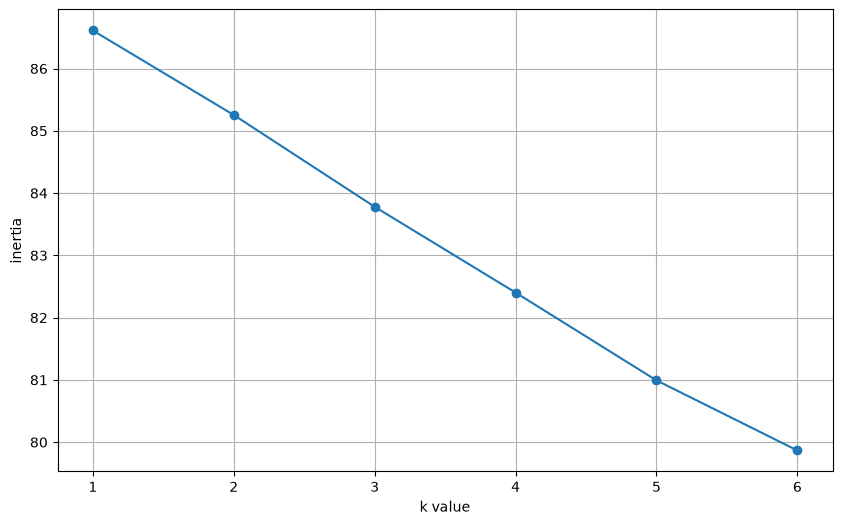

In [5]:
plt.figure(figsize=(10,6))
plt.plot(k, inertia, marker='o')
plt.xlabel('k value')
plt.ylabel('inertia')
plt.grid()
plt.show()

In [6]:
n_clusters = 4
kM = KMeans(n_clusters=n_clusters, random_state=10).fit(df_FE)
kM

,"n_clusters n_clusters: int, default=8The number of clusters to form as well as the number ofcentroids to generate.For an example of how to choose an optimal value for `n_clusters` refer to:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_silhouette_analysis.py`.",4
,"random_state random_state: int, RandomState instance or None, default=NoneDetermines random number generation for centroid initialization. Usean int to make the randomness deterministic.See :term:`Glossary <random_state>`.",10
,"init init: {'k-means++', 'random'}, callable or array-like of shape (n_clusters, n_features), default='k-means++'Method for initialization:* 'k-means++' : selects initial cluster centroids using sampling based on an empirical probability distribution of the points' contribution to the overall inertia. This technique speeds up convergence. The algorithm implemented is ""greedy k-means++"". It differs from the vanilla k-means++ by making several trials at each sampling step and choosing the best centroid among them.* 'random': choose `n_clusters` observations (rows) at random from data for the initial centroids.* If an array is passed, it should be of shape (n_clusters, n_features) and gives the initial centers.* If a callable is passed, it should take arguments X, n_clusters and a random state and return an initialization.For an example of how to use the different `init` strategies, see:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_digits.py`.For an evaluation of the impact of initialization, see the example:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_stability_low_dim_dense.py`.",'k-means++'
,"n_init n_init: 'auto' or int, default='auto'Number of times the k-means algorithm is run with different centroidseeds. The final results is the best output of `n_init` consecutive runsin terms of inertia. Several runs are recommended for sparsehigh-dimensional problems (see :ref:`kmeans_sparse_high_dim`).When `n_init='auto'`, the number of runs depends on the value of init:10 if using `init='random'` or `init` is a callable;1 if using `init='k-means++'` or `init` is an array-like... versionadded:: 1.2 Added 'auto' option for `n_init`... versionchanged:: 1.4 Default value for `n_init` changed to `'auto'`.",'auto'
,"max_iter max_iter: int, default=300Maximum number of iterations of the k-means algorithm for asingle run.",300
,"tol tol: float, default=1e-4Relative tolerance with regards to Frobenius norm of the differencein the cluster centers of two consecutive iterations to declareconvergence.",0.0001
,"verbose verbose: int, default=0Verbosity mode.",0
,"copy_x copy_x: bool, default=TrueWhen pre-computing distances it is more numerically accurate to centerthe data first. If copy_x is True (default), then the original data isnot modified. If False, the original data is modified, and put backbefore the function returns, but small numerical differences may beintroduced by subtracting and then adding the data mean. Note that ifthe original data is not C-contiguous, a copy will be made even ifcopy_x is False. If the original data is sparse, but not in CSR format,a copy will be made even if copy_x is False.",True
,"algorithm algorithm: {""lloyd"", ""elkan""}, default=""lloyd""K-means algorithm to use. The classical EM-style algorithm is `""lloyd""`.The `""elkan""` variation can be more efficient on some datasets withwell-defined clusters, by using the triangle inequality. However it'smore memory intensive due to the allocation of an extra array of shape`(n_samples, n_clusters)`... versionchanged:: 0.18 Added Elkan algorithm.. versionchanged:: 1.1 Renamed ""full"" to ""lloyd"", and deprecated ""auto"" and ""full"". Changed ""auto"" to use ""lloyd"" instead of ""elkan"".",'lloyd'
Name,Type,Value
"cluster_centers_ cluster_centers_: ndarray of shape (n_clusters, n_features)Coordinates of cluster centers. If the algorithm stops before fullyconverging (see ``tol`` and ``max_iter``), these will not beconsistent with ``labels_``.","ndarray[float64](4, 2754)"

In [7]:
df['Kmeans_label'] = kM.labels_
df.head()

,Halaman,Judul,Genre,Deskripsi,Harga,Kmeans_label
0,1,The Legend of Zelda: Ocarina of Time,"Action Adventure, Fantasy","As a young boy, Link is tricked by Ganondorf, ...","91,99 €",2
1,1,Super Mario Galaxy,"Action, Platformer, 3D",[Metacritic's 2007 Wii Game of the Year] The u...,"91,99 €",1
2,1,Super Mario Galaxy 2,"Action, Platformer, 3D","Super Mario Galaxy 2, the sequel to the galaxy...","91,99 €",1
3,1,Metroid Prime,"Action, Shooter, First-Person, Sci-Fi",Samus returns in a new mission to unravel the ...,"89,99 €",2
4,1,Super Mario Odyssey,"Action, Platformer, 3D",New Evolution of Mario Sandbox-Style Gameplay....,"89,99 €",1


Silhouette Score

In [8]:
from sklearn import metrics
labels = kM.labels_
metrics.silhouette_score(df_FE, labels, metric='euclidean')

0.0018062044337855026

Kmeans for cluster 0


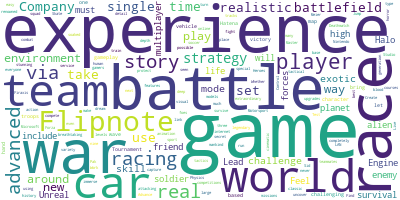

In [10]:
c = 0
print('Kmeans for cluster '+str(c))
df_c = df[df['Kmeans_label'] == c]
long_string = ','.join(list(df_c['Deskripsi'].values))
wordcloud = WordCloud(background_color="white", max_words=5000, contour_width=3)
wordcloud.generate(long_string)
wordcloud.to_image()

Kmeans for cluster 1


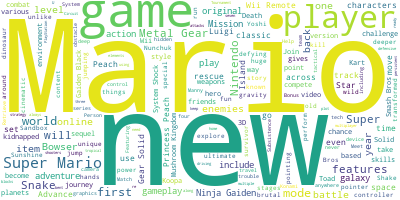

In [12]:
c = 1
print('Kmeans for cluster '+str(c))
df_c = df[df['Kmeans_label'] == c]
long_string = ','.join(list(df_c['Deskripsi'].values))
wordcloud = WordCloud(background_color="white", max_words=5000, contour_width=3)
wordcloud.generate(long_string)
wordcloud.to_image()

Kmeans for cluster 2


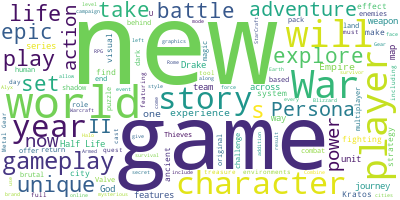

In [14]:
c = 2
print('Kmeans for cluster '+str(c))
df_c = df[df['Kmeans_label'] == c]
long_string = ','.join(list(df_c['Deskripsi'].values))
wordcloud = WordCloud(background_color="white", max_words=5000, contour_width=3)
wordcloud.generate(long_string)
wordcloud.to_image()

Kmeans for cluster 3


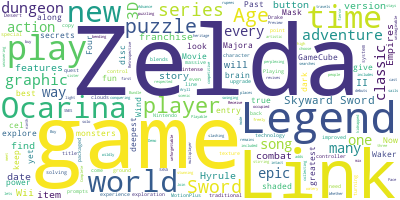

In [13]:
c = 3
print('Kmeans for cluster '+str(c))
df_c = df[df['Kmeans_label'] == c]
long_string = ','.join(list(df_c['Deskripsi'].values))
wordcloud = WordCloud(background_color="white", max_words=5000, contour_width=3)
wordcloud.generate(long_string)
wordcloud.to_image()

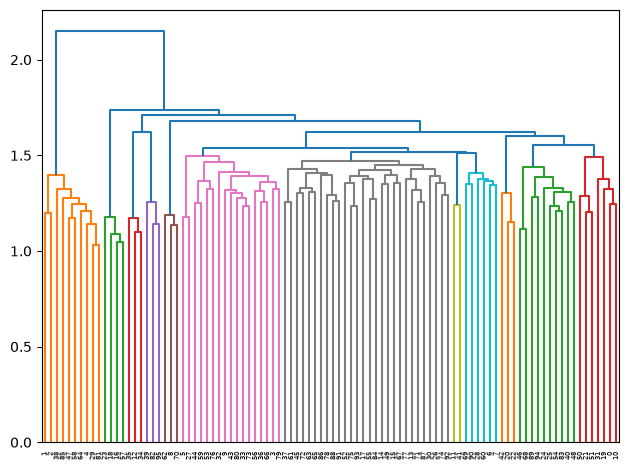

In [15]:
from scipy.cluster.hierarchy import dendrogram, linkage
linkage_data = linkage(df_FE, method = 'ward', metric = 'euclidean')
dendrogram(linkage_data)
plt.tight_layout()
plt.show()

Unsupervised: Hierarchical

In [59]:
from sklearn.cluster import AgglomerativeClustering
hierarchical_cluster = AgglomerativeClustering(n_clusters = n_clusters, linkage = 'ward')
labels = hierarchical_cluster.fit(df_FE)

pred_agc = pd.Series(hierarchical_cluster.labels_)
df['Ward_label'] = pred_agc

In [60]:
df.head()

,Halaman,Judul,Genre,Deskripsi,Harga,Ward_label
0,1,The Legend of Zelda: Ocarina of Time,"Action Adventure, Fantasy","As a young boy, Link is tricked by Ganondorf, ...","91,99 €",0
1,1,Super Mario Galaxy,"Action, Platformer, 3D",[Metacritic's 2007 Wii Game of the Year] The u...,"91,99 €",3
2,1,Super Mario Galaxy 2,"Action, Platformer, 3D","Super Mario Galaxy 2, the sequel to the galaxy...","91,99 €",3
3,1,Metroid Prime,"Action, Shooter, First-Person, Sci-Fi",Samus returns in a new mission to unravel the ...,"89,99 €",0
4,1,Super Mario Odyssey,"Action, Platformer, 3D",New Evolution of Mario Sandbox-Style Gameplay....,"89,99 €",3


In [61]:
from sklearn import metrics
labels = pred_agc
metrics.silhouette_score(df_FE, labels, metric='euclidean')

0.0010228666782792913

Hierarchical for cluster 0


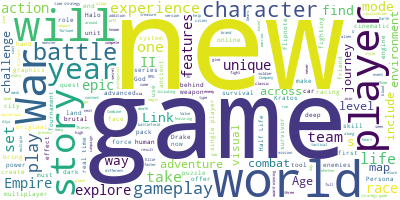

In [32]:
c = 0
print('Hierarchical for cluster '+str(c))
df_c = df[df['Ward_label'] == c]
long_string = ','.join(list(df_c['Deskripsi'].values))
wordcloud = WordCloud(background_color="white", max_words=5000, contour_width=3)
wordcloud.generate(long_string)
wordcloud.to_image()

Supervised: Sentiment Analysis

Game yang memuat: Adventure


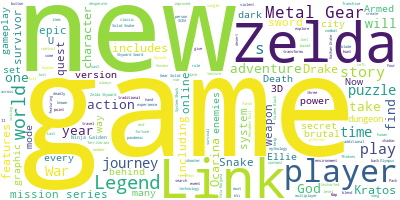

In [62]:
# from wordcloud import WordCloud
# c = 'Mario'
# print('Judul '+str(c))
# df_c = df[df['Judul'] == c]
# # print(df_c)
# long_string = ','.join(list(df_c['Deskripsi'].values))
# wordcloud = WordCloud(background_color="white", max_words=5000, contour_width=3)
# wordcloud.generate(long_string); display(wordcloud.to_image())


from wordcloud import WordCloud

c = 'Adventure'
print('Game yang memuat: ' + str(c))

# Gunakan str.contains agar mencakup semua judul yang ada kata 'Mario'
df_c = df[df['Genre'].str.contains(c, case=False, na=False)]

# Gabungkan teks Deskripsi menggunakan spasi ' ' (bukan koma ',')
clean_texts = df_c['Deskripsi'].dropna().astype(str)
long_string = ' '.join(clean_texts).strip()

# Buat WordCloud
if long_string:
    wordcloud = WordCloud(background_color="white", max_words=5000, contour_width=3)
    wordcloud.generate(long_string)
    display(wordcloud.to_image())
else:
    print(f"Tidak ada data dengan judul yang memuat kata '{c}'.")

Game memuat Action


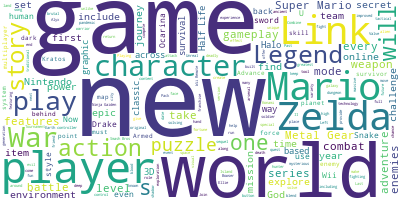

In [63]:
from wordcloud import WordCloud
c = 'Action'
print('Game memuat '+str(c))
df_c = df[df['Genre'].str.contains(c, case=False, na=False)]
long_string = ','.join(list(df_c['Deskripsi'].values))
wordcloud = WordCloud(background_color="white", max_words=5000, contour_width=3)
wordcloud.generate(long_string); wordcloud.to_image()

In [64]:
import pandas as pd
df = pd.read_csv('C:\Python\Github_Pemteks\Tugas_Pemrosesan_teks\produk_oxylabs.csv')
df = df.dropna().reset_index().drop(columns=['index'])
df_pre = df['Deskripsi']

# Mengubah teks menjadi matriks TF-IDF
from sklearn.feature_extraction.text import TfidfVectorizer
vectorizer = TfidfVectorizer()
vecs = vectorizer.fit_transform(df_pre)
vecs

<>:2: SyntaxWarning: "\P" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\P"? A raw string is also an option.
<>:2: SyntaxWarning: "\P" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\P"? A raw string is also an option.
C:\Users\JOSHUA\AppData\Local\Temp\ipykernel_19472\3358563247.py:2: SyntaxWarning: "\P" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\P"? A raw string is also an option.
  df = pd.read_csv('C:\Python\Github_Pemteks\Tugas_Pemrosesan_teks\produk_oxylabs.csv')


<Compressed Sparse Row sparse matrix of dtype 'float64'
	with 6824 stored elements and shape (96, 2754)>

In [72]:
# Classify
X = vecs # FE result
y = df['Genre']

from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.30, random_state=42)

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix

model = RandomForestClassifier()
model.fit(X_train, y_train)
y_pred = model.predict(X_test)
print(confusion_matrix(y_test, y_pred))
print(classification_report(y_test, y_pred))

[[0 0 0 0 0 0 0 1 0 1 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]
 [1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]
 [1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0]
 [1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]
 [1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 2 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0]
 [1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0 1 0 0 1 0 0

c:\Users\JOSHUA\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\ensemble\_forest.py:811: UserWarning: The number of unique classes is greater than 50% of the number of samples. `y` could represent a regression problem, not a classification problem.
  check_classification_targets(y)
c:\Users\JOSHUA\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\tree\_classes.py:289: UserWarning: The number of unique classes is greater than 50% of the number of samples. `y` could represent a regression problem, not a classification problem.
  check_classification_targets(y)
c:\Users\JOSHUA\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\tree\_classes.py:289: UserWarning: The number of unique classes is greater than 50% of the number of samples. `y` could represent a regression problem, not a classification problem.
  check_classification_targets(y)
c:\Users\JOSHUA\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\tree\_classes.py:289:

In [77]:
testing = "Local"
testing = vectorizer.transform([testing])
testing = model.predict(testing)
print(testing)

['Driving, Racing, GT / Street']
